# Homework # 4 Naive BAYES Classifier

### Instructor - Dr. Uma Gajendragadkar

### Problem - Design and develop Machine learning model to predict Diabetes using Naive Bayes Algorithm. 

### Dataset - Diabetes dataset

This dataset consists of 768 observations & 8 numerical independent variables.
Dependent and target variable is OUTCOME. 1 means diabetes test result being positive, 0 means indicates negative.

Pregnancies: Number of Times Being Pregnant

Glucose: Plasma Glucose Concentration (a 2 hours in an oral glucose tolerance test)

BloodPressure: Diastolic Blood Pressure (mm Hg)

SkinThickness: Triceps Skin Fold Thickness (mm)

Insulin: 2-Hour Serum Insulin (mu U/ml)

BMI: Body Mass Index (weight in kg/(height in m)^2)

DiabetesPedigreeFunction: Diabetes Pedigree Function

Age: Age

Outcome: Class variable ( 0 - 1)



In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import MinMaxScaler, LabelEncoder, StandardScaler, RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, classification_report
from sklearn.model_selection import train_test_split, cross_validate
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.3f' % x)
pd.set_option('display.width', 500)
import warnings
warnings.filterwarnings('ignore')
import matplotlib.pyplot  as plt
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn import preprocessing
from sklearn.naive_bayes import GaussianNB

Step 1 - Write code to Read data from dataset into pandas dataframe

In [2]:
df = pd.read_csv("diabetes.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.600,0.627,50,1
1,1,85,66,29,0,26.600,0.351,31,0
2,8,183,64,0,0,23.300,0.672,32,1
3,1,89,66,23,94,28.100,0.167,21,0
4,0,137,40,35,168,43.100,2.288,33,1


Step 2 - a) Write code to display dataset info 
b) Print 10 rows from dataset.

In [3]:
print("Dataset information:")
df.info()

print("\nFirst 10 rows:")
display(df.head(10))

print("\nDataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

First 10 rows:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.600,0.627,50,1
1,1,85,66,29,0,26.600,0.351,31,0
2,8,183,64,0,0,23.300,0.672,32,1
3,1,89,66,23,94,28.100,0.167,21,0
4,0,137,40,35,168,43.100,2.288,33,1
5,5,116,74,0,0,25.600,0.201,30,0
6,3,78,50,32,88,31.000,0.248,26,1
7,10,115,0,0,0,35.300,0.134,29,0
8,2,197,70,45,543,30.500,0.158,53,1
9,8,125,96,0,0,0.000,0.232,54,1



Dataset shape: (768, 9)

Column names: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']


Step 3 - Write code to remove Pregnancy column 

In [4]:
df = df.drop(columns=["Pregnancies"])
df.head()

,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,148,72,35,0,33.600,0.627,50,1
1,85,66,29,0,26.600,0.351,31,0
2,183,64,0,0,23.300,0.672,32,1
3,89,66,23,94,28.100,0.167,21,0
4,137,40,35,168,43.100,2.288,33,1


Step 4 - Write code to display info of dataset and check shape of dataset.

In [5]:
print("Updated dataset information:")
df.info()

print("\nUpdated dataset shape:", df.shape)

Updated dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Glucose                   768 non-null    int64  
 1   BloodPressure             768 non-null    int64  
 2   SkinThickness             768 non-null    int64  
 3   Insulin                   768 non-null    int64  
 4   BMI                       768 non-null    float64
 5   DiabetesPedigreeFunction  768 non-null    float64
 6   Age                       768 non-null    int64  
 7   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(6)
memory usage: 48.1 KB

Updated dataset shape: (768, 8)


Step 5 - Write code to clean data

Missing values in each column:
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Zero values before cleaning:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Missing values after cleaning:
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Outcome counts:
Outcome
0    500
1    268
Name: count, dtype: int64


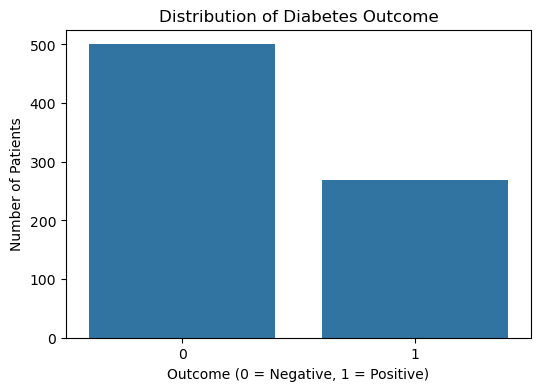

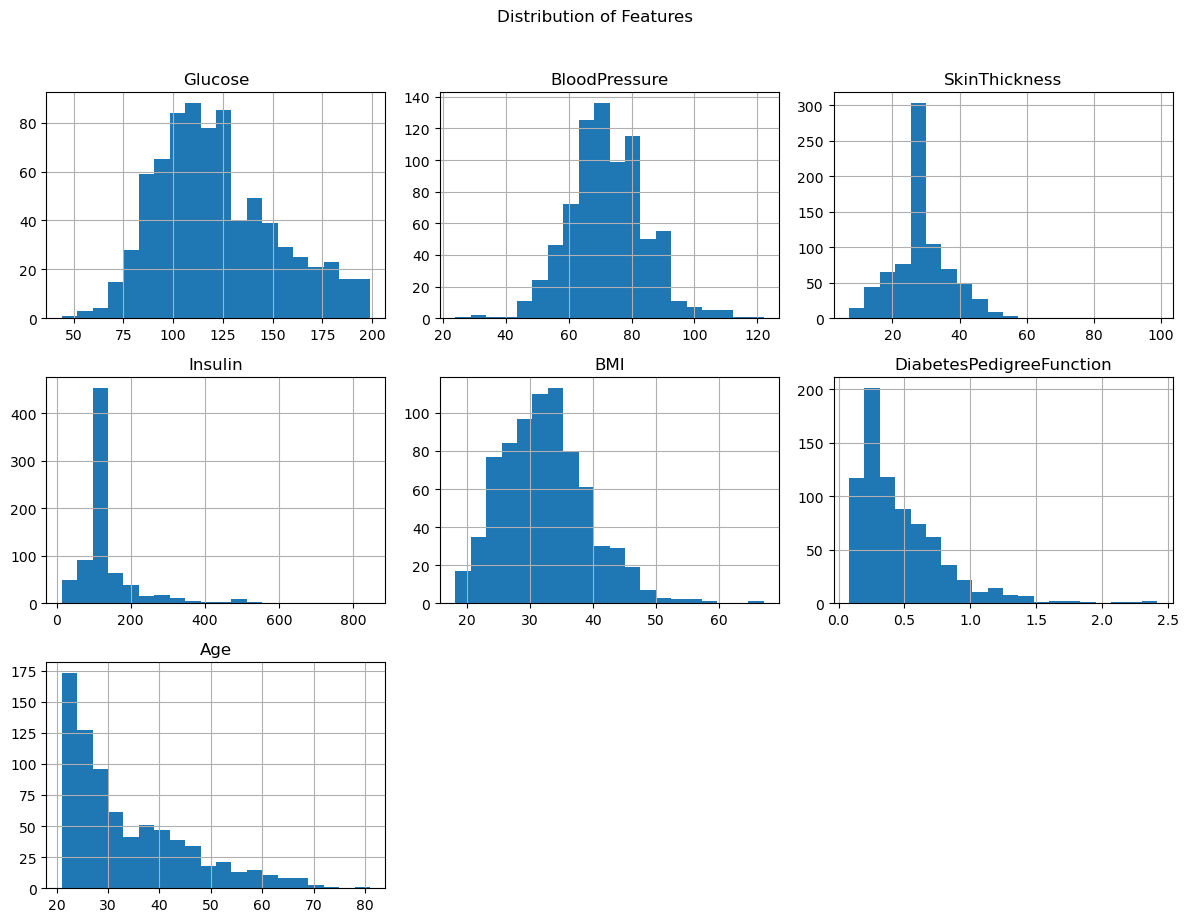

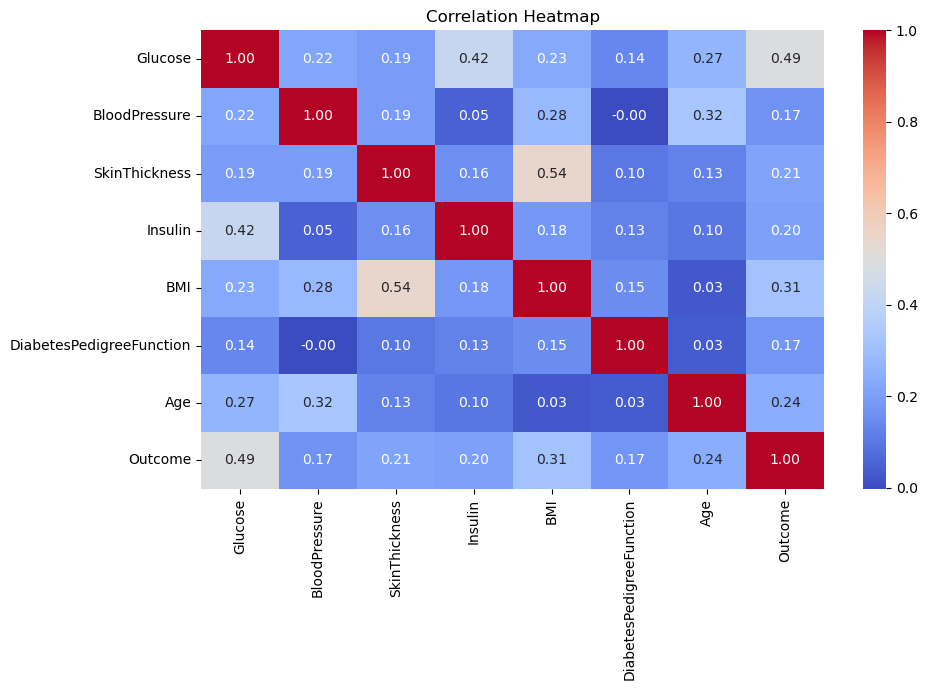

In [6]:
print("Missing values in each column:")
print(df.isnull().sum())
medical_columns = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

print("\nZero values before cleaning:")
print((df[medical_columns] == 0).sum())

df[medical_columns] = df[medical_columns].replace(0, np.nan)
for column in medical_columns:
    df[column] = df[column].fillna(df[column].median())

print("\nMissing values after cleaning:")
print(df.isnull().sum())


print("\nOutcome counts:")
print(df["Outcome"].value_counts())


plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Outcome")
plt.title("Distribution of Diabetes Outcome")
plt.xlabel("Outcome (0 = Negative, 1 = Positive)")
plt.ylabel("Number of Patients")
plt.show()

df.drop(columns=["Outcome"]).hist(figsize=(12, 9), bins=20)
plt.suptitle("Distribution of Features", y=1.02)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 7))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

Step 6 - Split data into training and testing sets ( 80: 20 ratio)

In [7]:
X = df.drop(columns=["Outcome"])
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training features shape: (614, 7)
Testing features shape: (154, 7)
Training target shape: (614,)
Testing target shape: (154,)


#### **Step #7: Initialize your model**




In [8]:
model = GaussianNB()
model

,priors,None
,var_smoothing,1e-09


#### **Step #8: Fit your model, test on the testing data, and create a visualization if applicable**

In [9]:
model.fit(X_train, y_train)

print("Gaussian Naive Bayes model training completed.")

y_pred = model.predict(X_test)

Gaussian Naive Bayes model training completed.


Step 9 - Predict using model on test data

In [10]:
print("Predicted outcomes:")
print(y_pred[:20])

print("\nActual outcomes:")
print(y_test.iloc[:20].to_numpy())

Predicted outcomes:
[0 0 0 0 0 0 1 1 0 1 0 0 0 1 0 0 1 0 1 0]

Actual outcomes:
[0 0 0 1 0 0 1 1 0 0 0 1 0 0 1 1 0 0 0 0]


Step 10 -  Find accuracy of model

In [12]:
accuracy = accuracy_score(y_test, y_pred)
print("Model Accuracy: {:.2f}%".format(accuracy * 100))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["No Diabetes", "Diabetes"]))

y_probability = model.predict_proba(X_test)[:, 1]
print("ROC-AUC Score: {:.3f}".format(roc_auc_score(y_test, y_probability)))

Model Accuracy: 68.83%

Classification Report:
              precision    recall  f1-score   support

 No Diabetes       0.75      0.77      0.76       100
    Diabetes       0.56      0.54      0.55        54

    accuracy                           0.69       154
   macro avg       0.66      0.65      0.65       154
weighted avg       0.69      0.69      0.69       154

ROC-AUC Score: 0.750


Step 11 - Confusion Matrix

Confusion Matrix:
[[77 23]
 [25 29]]


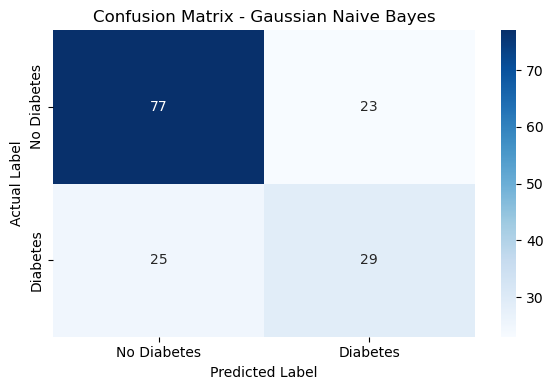

In [13]:
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"]
)
plt.title("Confusion Matrix - Gaussian Naive Bayes")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

In [14]:
print("The Gaussian Naive Bayes classifier was trained and evaluated on the diabetes dataset.")
print("Review the accuracy, classification report, ROC-AUC score, and confusion matrix above.")
print("This model is for educational purposes and is not a medical diagnostic tool.")

The Gaussian Naive Bayes classifier was trained and evaluated on the diabetes dataset.
Review the accuracy, classification report, ROC-AUC score, and confusion matrix above.
This model is for educational purposes and is not a medical diagnostic tool.
